# 05. 파생변수 확정 — seller_avg_delay·카테고리·거리 결측 (Day 5)

| 항목 | 내용 |
|---|---|
| 목적 | 1·2단계 공통 X 파생변수를 확정하고 모델 입력/금지 목록을 고정 |
| 입력 | `data/processed/master.parquet` |
| 출력 | `data/processed/master_features.parquet`(96,204행 × 30컬럼) — 07·08의 입력 |
| 관련 결정 | D-01(seller_avg_delay), D-02(카테고리 상위 22), D-04(거리 결측 대체), D-16(입력 목록) |
| 핵심 결과 | seller_avg_delay = 구매 시점 이전 배송완료분 late 누적, min_n=20(fallback 32.4%) / 카테고리 22개+미상+기타 / 거리 결측 477건을 고객 주 학습구간 평균으로 대체 |

> **읽는 법**: 맨 아래 「결론」 셀에 최종 결과가 있다. 본문의 `[YYYY-MM-DD 정정·추가]` 표시는 고친 이력이며, 최종 판단은 결론 셀과 `docs/decisions.md`를 따른다.

---

## 결정 배경: D-01 seller_avg_delay 산출 방식

**[2026-09-28 개정 2]** 계획서 원안(3절: 셀러별 과거 지연 비율 = 지연건수/전체건수, 0\~1)을 따르되, **"과거 주문"을 "현재 주문의 구매시각 이전에 이미 배송이 끝나 late를 알 수 있는 주문"으로 정의**한다.

- 이전 버전(v3까지)은 "구매시각이 더 이른 주문"의 late를 썼는데, 그 주문이 아직 배송 중이면 late는 예측 시점에 알 수 없는 값이다(라벨 가용시점 누출). 2-0 셀에서 두 방식을 비교: late와 상관 0.0956→0.0274, 단변량 AUC 0.6017→0.5439로 크게 하락 → 이전 버전의 성능은 부풀려져 있었음
- 그래서 v3까지의 min_n 표·정의 비교 수치(0.0956, AUC 0.6017/0.6089 등)는 **누출 버전 수치이므로 decisions.md에 인용하지 말 것**. 2-1, 2-2는 배송완료 기준으로 다시 계산
- LOO/OOF/expanding 비교(04 cell54\~55)는 "구매 순서상 미래정보를 쓰는가"만 본 것이라 이 라벨 가용시점 문제는 다루지 못했음
- 판단기준(결과 보기 전 고정, 우선순위 ②>①>③): ①셀러별 산출값 안정성 ②미래정보 누출 여부(구매순서 + 라벨 가용시점) ③구현난이도
- 대표셀러는 `master.seller_rep`(03_master.ipynb 셀 4·9에서 확정: 거리최대, tie는 `order_item_id ASC`, D-12)를 그대로 사용 (item_base 재계산 결과와 96,204건 전부 일치 확인)
- 한계: 예측 시점은 계획서상 주문 승인 시점이나 구매시각(purchase_ts)을 기준으로 근사(승인까지 보통 수 시간). 분석기간 맨 앞 소수 주문은 전역 이력도 없어 이후 첫 유효값으로 채움(6번 셀에서 건수 확인)


## 0. 데이터 로드

In [1]:
import numpy as np
import pandas as pd
from src import my_stats

master = pd.read_parquet("data/processed/master.parquet")
assert master["order_id"].is_unique and len(master) == 96204

# delivery_error_days는 master.parquet에 저장돼 있지 않음 — 04_eda 7절에서
# 세션 내 임시로만 계산했던 컬럼이라 여기서 다시 만들어줘야 함 (2-1 비교용)
master["delivery_error_days"] = (master.order_delivered_customer_date
                                  - master.order_estimated_delivery_date).dt.days


## 1. seller_avg_delay 함수 정의

In [2]:
MIN_N = 20          # D-01 확정값 — 2-2 셀(학습기간만 재검토) 결과 기준, min_n=20→30에서
                    # corr_vs_late 차이(0.0682→0.0700, Δ=0.0018)는 잡음 수준이라 fallback
                    # 비율이 더 낮은 20 채택 (decisions.md D-01 참고)


def _expanding_by_purchase_order(df: pd.DataFrame, value_col: str, min_n: int):
    """[비교용 — 누출 있음, 실제 피처에는 쓰지 말 것]
    구매시각이 더 이른 주문의 value_col 누적평균. 그 주문이 아직 배송 전이어도 값을 씀."""
    cum_sum = df.groupby("seller_id")[value_col].cumsum() - df[value_col]
    cum_cnt = df.groupby("seller_id").cumcount()
    seller_val = cum_sum / cum_cnt.replace(0, np.nan)
    g_cum_sum = df[value_col].cumsum() - df[value_col]
    g_cum_cnt = pd.Series(np.arange(len(df)), index=df.index)
    global_val = (g_cum_sum / g_cum_cnt.replace(0, np.nan)).fillna(df[value_col].iloc[0])
    use_fb = cum_cnt < min_n
    return np.where(use_fb, global_val, seller_val), use_fb


def _delivered_only_with_fallback(df: pd.DataFrame, value_col: str, min_n: int):
    """
    각 주문의 구매시각(purchase_ts) 이전에 '배송이 이미 끝난' 같은 셀러 주문들의
    value_col 평균(지연비율이면 late 평균)을 계산한다. 배송완료 시각 <= 구매시각인 주문만 사용.
    그런 셀러 주문이 min_n건 미만이면 같은 기준(구매시각 이전 배송완료)의 전역 평균으로 대체.
    전제: df는 RangeIndex, seller_id / purchase_ts / order_delivered_customer_date / value_col 보유.
    반환: (값 배열, fallback 여부 Series)
    """
    assert df.index.equals(pd.RangeIndex(len(df))), "reset_index(drop=True) 필요"
    assert df["order_delivered_customer_date"].notna().all()
    n = len(df)
    s_sum, s_cnt = np.zeros(n), np.zeros(n)

    for _, g in df.groupby("seller_id"):
        ev = g.sort_values("order_delivered_customer_date")
        t = ev["order_delivered_customer_date"].to_numpy()
        cs = np.cumsum(ev[value_col].to_numpy())
        idx = np.searchsorted(t, g["purchase_ts"].to_numpy(), side="right")  # 구매시각 이전 배송완료 건수
        s_cnt[g.index] = idx
        s_sum[g.index] = np.where(idx > 0, cs[np.maximum(idx - 1, 0)], 0.0)

    ev = df.sort_values("order_delivered_customer_date")
    t = ev["order_delivered_customer_date"].to_numpy()
    cs = np.cumsum(ev[value_col].to_numpy())
    idx = np.searchsorted(t, df["purchase_ts"].to_numpy(), side="right")
    g_mean = np.where(idx > 0, cs[np.maximum(idx - 1, 0)] / np.maximum(idx, 1), np.nan)
    g_mean = pd.Series(g_mean).bfill().to_numpy()   # 전역 이력도 없는 맨 앞 소수 주문만 첫 유효값으로 채움

    use_fb = s_cnt < min_n
    return np.where(use_fb, g_mean, s_sum / np.maximum(s_cnt, 1)), pd.Series(use_fb, index=df.index)


def add_seller_avg_delay(master: pd.DataFrame, min_n: int = MIN_N) -> pd.DataFrame:
    """
    master에 seller_avg_delay, seller_avg_delay_is_fallback 컬럼을 추가해 반환한다.

    seller_avg_delay: 현재 주문의 구매시각 이전에 배송이 끝난 같은 셀러 주문들의 지연 비율
    (late 평균, 0~1). 계획서 3절 정의(지연건수/전체건수)에 '라벨을 알 수 있는 시점'을 반영.
    해당 주문이 min_n건 미만이면 같은 기준의 전역 지연비율로 대체.
    대표셀러는 master.seller_rep(D-12, 03_master.ipynb에서 확정) 사용.
    """
    df = master.copy()
    df["seller_id"] = df["seller_rep"]
    df = df.sort_values(["purchase_ts", "order_id"]).reset_index(drop=True)

    vals, use_fallback = _delivered_only_with_fallback(df, "late", min_n)
    df["seller_avg_delay"] = vals
    df["seller_avg_delay_is_fallback"] = use_fallback.to_numpy()

    assert df["seller_avg_delay"].isna().sum() == 0, "결측 발생 — min_n/데이터 확인 필요"
    assert df["seller_avg_delay"].between(0, 1).all(), "0~1 범위 벗어남 — late 컬럼 확인 필요"
    return df


## 2. 적용 및 검증

In [3]:
master = add_seller_avg_delay(master)

print("seller_avg_delay 결측:", master["seller_avg_delay"].isna().sum())
print("fallback 적용 비율:", round(master["seller_avg_delay_is_fallback"].mean(), 4))
# 전역 이력조차 없는 맨 앞 주문 수(첫 배송완료 이전에 구매된 주문) — 이 주문들만 첫 유효값으로 채워짐
print("전역 이력 없는 주문 수:", int((master["purchase_ts"] < master["order_delivered_customer_date"].min()).sum()))
master["seller_avg_delay"].describe()


seller_avg_delay 결측: 0
fallback 적용 비율: 0.324
전역 이력 없는 주문 수: 60


count    96204.000000
mean         0.046559
std          0.038839
min          0.000000
25%          0.023700
50%          0.037855
75%          0.066758
max          0.521739
Name: seller_avg_delay, dtype: float64

## 2-0. 누출 확인 — 구매순서 누적 vs 배송완료분만 + 학습기간 한정 준비

두 방식을 같은 min_n에서 비교한다. AUC는 **모델 학습이 아니라 피처 값 하나로 late를 순위매긴 단변량 AUC**다.
사전 기준(결과 보기 전): 배송완료 방식에서 AUC가 크게 떨어지면(예: 0.55 부근) 구매순서 방식은 라벨 가용시점 누출로 성능이 부풀려진 것으로 본다.


아래부터(2-0 코드 셀 이후) `train_only`(purchase_ts < 2018-05-01)를 정의하고, **2-1·2-2는 전부 이 train_only로 계산한다.** 테스트 구간(2018-05\~08) 주문의 실제 late 값이 정의·min_n 같은 하이퍼파라미터 선택에 들어가면 그 자체가 (작지만) 정보 누출이기 때문.


In [4]:
from sklearn.metrics import roc_auc_score

d = master.copy()   # add_seller_avg_delay 이후 master는 purchase_ts 정렬 + RangeIndex + seller_id 포함
v_leak, _ = _expanding_by_purchase_order(d, "late", MIN_N)
v_ok, _ = _delivered_only_with_fallback(d, "late", MIN_N)

print("late와 상관  — 구매순서(누출):", round(np.corrcoef(v_leak, d["late"])[0, 1], 4),
      "/ 배송완료분만:", round(np.corrcoef(v_ok, d["late"])[0, 1], 4))
print("단변량 AUC   — 구매순서(누출):", round(roc_auc_score(d["late"], v_leak), 4),
      "/ 배송완료분만:", round(roc_auc_score(d["late"], v_ok), 4))
print("두 방식 간 상관:", round(np.corrcoef(v_leak, v_ok)[0, 1], 4))


late와 상관  — 구매순서(누출): 0.0956 / 배송완료분만: 0.0274
단변량 AUC   — 구매순서(누출): 0.6017 / 배송완료분만: 0.5439
두 방식 간 상관: 0.8158


In [5]:
# [2026-09-29] train_only 정의 — 이후 2-1·2-2는 전부 이 데이터로 계산한다
# (테스트 구간 라벨이 정의·min_n 선택에 섞이는 것을 차단)
train_only = d[d["purchase_ts"] < "2018-05-01"].reset_index(drop=True)
print(f"train_only: {len(train_only)}행 (전체 {len(d)}행 중 학습기간)")

print("\n=== baseline (전역 late율만 쓴 경우) ===")
baseline_auc = roc_auc_score(train_only["late"], [train_only["late"].mean()] * len(train_only))
print("전역 평균 baseline AUC:", round(baseline_auc, 4), "(상수값이라 항상 0.5 — 참고용)")

print("\n=== fallback vs non-fallback 분리 (학습기간만, min_n=20) ===")
v_tr, fb_tr = _delivered_only_with_fallback(train_only, "late", MIN_N)
for name, mask in [("non-fallback", ~fb_tr), ("fallback", fb_tr)]:
    sub_v, sub_y = v_tr[mask.values], train_only.loc[mask.values, "late"]
    if sub_y.nunique() > 1:
        print(f"{name}: n={mask.sum()}, AUC={roc_auc_score(sub_y, sub_v):.4f}")
# 한계: fallback(시점별 전역 late율) AUC가 non-fallback(진짜 셀러 이력)보다 높게 나오면
# seller_avg_delay 신호의 상당 부분이 셀러 고유 품질이 아니라 시기 효과를 대리하는 것 —
# 변수를 해석할 때 셀러 고유 품질이 아니라 셀러+시기 혼합 신호로 서술한다(D-01 한계 2)
# [2026-09-30 추가] 다만 fallback 집단(s_cnt<20)은 구조적으로 신규·초반 셀러에 몰려 있어
# (fallback = 아직 이력이 min_n 미만인 주문), non-fallback과의 AUC 비교가 '셀러 이력 유무'만
# 순수 비교한 건 아님 — 신규셀러 효과와 뒤섞여 있을 수 있다는 교란 요인이 있다(D-01 한계 2에 기록)


train_only: 70852행 (전체 96204행 중 학습기간)

=== baseline (전역 late율만 쓴 경우) ===
전역 평균 baseline AUC: 0.5 (상수값이라 항상 0.5 — 참고용)

=== fallback vs non-fallback 분리 (학습기간만, min_n=20) ===
non-fallback: n=46806, AUC=0.5855
fallback: n=24046, AUC=0.6236


## 2-1. 정의 비교 — late 비율(계획서 원안) vs delivery_error_days 평균 (배송완료 기준)

두 정의 모두 같은 '배송완료분만' 로직으로 다시 계산한다. 해석 기준(결과 보기 전 고정): 두 값의 차이가 0.01 미만이면 "차이 없음"으로 보고 계획서 원안 유지.


In [6]:
v_late, _ = _delivered_only_with_fallback(train_only, "late", MIN_N)
v_days, _ = _delivered_only_with_fallback(train_only, "delivery_error_days", MIN_N)

print("두 정의 간 상관:", round(np.corrcoef(v_late, v_days)[0, 1], 4))
print("late와의 상관  — late비율:", round(np.corrcoef(v_late, train_only["late"])[0, 1], 4),
      "/ delay_days:", round(np.corrcoef(v_days, train_only["late"])[0, 1], 4))
print("단변량 AUC     — late비율:", round(roc_auc_score(train_only["late"], v_late), 4),
      "/ delay_days:", round(roc_auc_score(train_only["late"], v_days), 4))


두 정의 간 상관: 0.5709
late와의 상관  — late비율: 0.0682 / delay_days: 0.0815
단변량 AUC     — late비율: 0.5947 / delay_days: 0.6074


**결정**: train_only 기준으로도 상관·AUC 모두 delay_days가 우세(상관 0.0682 vs 0.0815, AUC 0.5947 vs 0.6074,
차이 0.01 초과)하지만, 계획서 원안(late 비율)을 유지한다. 근거는 데이터 우위가 아니라 (1) 승인된 계획서 준수,
(2) 원안이 되돌리기 쉬움. delay_days는 Day6 모델에서 후보로 비교해 채택 여부를 결정한다(decisions.md D-01 참고). [2026-10-30: Day 6에서 이 비교는 하지 않았다. 이유는 D-01 마지막 항목]


## 2-2. min_n 재검토 (배송완료 기준)

min_n 후보 5/10/20/30/50에 대해 fallback 비율·std·late와의 상관을 계산한다.
std 감소는 구간 폭(5,10,10,20)이 달라 `Δstd`를 그대로 비교하면 안 되므로 **구간 폭으로 나눈 Δstd/Δmin_n**으로 본다.


In [7]:
rows = []
for mn in [5, 10, 20, 30, 50]:
    vals, fb = _delivered_only_with_fallback(train_only, "late", mn)
    rows.append({
        "min_n": mn,
        "fallback_비율": round(fb.mean(), 4),
        "std": round(pd.Series(vals).std(), 4),
        "max": round(pd.Series(vals).max(), 4),
        "corr_vs_late": round(np.corrcoef(vals, train_only["late"])[0, 1], 4),
    })
tbl = pd.DataFrame(rows)
tbl["Δstd/Δmin_n"] = (tbl["std"].shift(1) - tbl["std"]) / (tbl["min_n"] - tbl["min_n"].shift(1))
print(tbl.to_string(index=False))
# 판단: Δstd/Δmin_n이 급격히 꺾이는 지점(elbow)이 없으면 fallback 비율·상관을 함께 보고 절충 (결과 보고 확정)


 min_n  fallback_비율    std    max  corr_vs_late  Δstd/Δmin_n
     5       0.1585 0.0428 1.0000        0.0576          NaN
    10       0.2349 0.0373 0.7000        0.0629     0.001100
    20       0.3394 0.0322 0.5217        0.0682     0.000510
    30       0.4143 0.0292 0.4242        0.0700     0.000300
    50       0.5155 0.0263 0.3303        0.0676     0.000145


## 2-3. (부록) 미래정보를 쓰는 방식과의 late 기준 비교 — LOO·OOF vs 확정 방식

**목적**: 04 노트북 '파생변수 생성 예비작업' 절의 LOO·OOF·expanding 비교는 `delivery_error_days` 기준의 구조적 비교(산출값 상관·결측 규모)였고, late 예측력은 보지 않았다. 아래에서 **학습기간(`train_only`)만으로** late 기준 상관·단변량 AUC를 확인한다(decisions.md D-01 경과 4 근거).

- **선택 근거가 아니라 참고용**이다. 방식 선택은 "구매 순서상 미래정보를 쓰는가"(구조적 판단, 우선순위 ②)로 했고, 성능으로 고르지 않았다.
- LOO: 전체(미래 주문 포함)에서 자기만 제외. OOF: 시간을 무시한 무작위 5-fold. 둘 다 미래 주문의 라벨을 씀.
- **주의**: LOO·OOF에는 min_n 규칙(이력 20건 미만이면 전역값 대체)이 없어, 확정 방식과 완전히 같은 조건의 비교가 아니다. 결과의 차이에는 누출 효과와 min_n 효과가 섞여 있어 누출만의 효과로 분리하지 못한다.
- 라벨 가용시점 누출(배송 전 주문의 late 사용)은 이 비교로 잡히지 않으며, 2-0에서 따로 확인함.


In [8]:
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

t = train_only.copy()   # 학습기간만 (테스트 라벨 배제)

# LOO: 전체(미래 포함)에서 자기만 제외
g = t.groupby("seller_id")["late"]
loo = (g.transform("sum") - t["late"]) / (g.transform("count") - 1)
loo = loo.fillna(t["late"].mean())

# OOF: 시간 무시 무작위 5-fold
oof = pd.Series(np.nan, index=t.index)
for tr, va in KFold(5, shuffle=True, random_state=42).split(t):
    m = t.iloc[tr].groupby("seller_id")["late"].mean()
    oof.iloc[va] = t.iloc[va]["seller_id"].map(m).values
oof = oof.fillna(t["late"].mean())

# 시간순 + 배송완료분만 (확정 방식)
ok, _ = _delivered_only_with_fallback(t, "late", MIN_N)

for name, v in [("LOO", loo), ("OOF", oof), ("배송완료 expanding", ok)]:
    print(f"{name}: corr={np.corrcoef(v, t['late'])[0,1]:.4f}, AUC={roc_auc_score(t['late'], v):.4f}")

LOO: corr=0.1171, AUC=0.6153
OOF: corr=0.1117, AUC=0.6136
배송완료 expanding: corr=0.0682, AUC=0.5947


## 3. category 파생변수 — D-02: 상위 22개 + 미상(별도) + 기타

결정 근거는 decisions.md D-02 참고(2026-09-27 확정). 요약:

- 카테고리 랭킹에 "미상"(결측, 1,376건)이 진짜 카테고리와 섞여있던 걸 발견 → 미상을 먼저 빼고 71개 실제 카테고리만으로 상위N 커버율 재계산
- 미상 제외 기준 80%→16개/90%→22개/95%→32개 → **90% 커버율 기준**으로 22 채택(21개는 89.46%, 22개는 90.25%로 처음 90%를 넘는 지점). [2026-09-30 정정] 초기엔 rank18→19·rank21→22의 감소율(-25.8%/-25.7%)이 "자연스러운 단절점"이라고 서술했으나, rank7→8도 동일 크기(-25.69%)로 떨어져 특별한 신호가 아님을 재확인 — 근거를 90% 커버율 기준으로 단일화
- 위 커버율·감소율은 아래 3-0 셀에서 계산한다(04 11절은 '미상'을 포함해 세서 90%가 23개로 나온다)
- `category_grouped`: 상위 22개(개별 유지) + 미상(N값과 무관하게 항상 별도) + 나머지 49개(기타)
- 상위 22개 순위는 전체 기간(테스트 구간 포함) 주문 수로 정했다. 라벨을 쓰지 않아 누수는 아니며, 학습 기간(2018-05 이전)만으로 정해도 상위 22개가 똑같다(아래 4절 assert, 2026-10-30 확인)


In [9]:
# 3-0. D-02 근거: '미상'을 뺀 실제 카테고리(주문 단위 대표 카테고리)의 누적 커버율과 순위별 감소율
# 04 11절은 '미상'을 포함해 세서 90%가 23개로 나온다. D-02는 미상을 랭킹에서 빼고 항상 별도로 두므로 여기서 다시 센다.
_cat = master.loc[master["category_en"] != "미상", "category_en"].value_counts()
_cov = (_cat / _cat.sum()).cumsum()
n_cat = {p: int((_cov < p).sum() + 1) for p in (0.8, 0.9, 0.95)}
_drop = (_cat / _cat.shift(1) - 1) * 100          # 바로 위 순위 대비 주문 수 감소율(%)
print("실제 카테고리 수:", len(_cat), "| 누적 커버율 80/90/95%에 필요한 개수:", n_cat)
print(f"상위 21개 {_cov.iloc[20] * 100:.2f}% / 상위 22개 {_cov.iloc[21] * 100:.2f}% (22개에서 처음 90%를 넘음)")
print(f"감소율: rank7→8 {_drop.iloc[7]:.2f}%, rank18→19 {_drop.iloc[18]:.2f}%, rank21→22 {_drop.iloc[21]:.2f}%"
      " (세 곳이 비슷해 '단절점' 근거로 쓰지 않음)")
assert len(_cat) == 71 and n_cat == {0.8: 16, 0.9: 22, 0.95: 32}
assert (round(_cov.iloc[20] * 100, 2), round(_cov.iloc[21] * 100, 2)) == (89.46, 90.25)

실제 카테고리 수: 71 | 누적 커버율 80/90/95%에 필요한 개수: {0.8: 16, 0.9: 22, 0.95: 32}
상위 21개 89.46% / 상위 22개 90.25% (22개에서 처음 90%를 넘음)
감소율: rank7→8 -25.69%, rank18→19 -25.80%, rank21→22 -25.75% (세 곳이 비슷해 '단절점' 근거로 쓰지 않음)


In [10]:
CATEGORY_TOP_N = 22   # D-02 확정값 (미상 제외 기준 90% 커버)


def add_category_grouped(master: pd.DataFrame, top_n: int = CATEGORY_TOP_N) -> pd.DataFrame:
    """
    master에 category_grouped 컬럼을 추가해 반환한다.

    규칙: "미상"은 랭킹에서 제외하고 항상 별도 카테고리로 유지한다(D-02 근거 참고 —
    미상을 카운트 랭킹에 섞으면 top_n 값에 따라 미상이 상위/기타로 흔들리는 문제가 있었음).
    미상을 제외한 실제 카테고리 중 주문수 상위 top_n개는 그대로 유지하고,
    나머지는 "기타"로 묶는다.
    """
    df = master.copy()

    known = df.loc[df["category_en"] != "미상", "category_en"]
    top_categories = known.value_counts().head(top_n).index

    def _group(cat):
        if cat == "미상":
            return "미상"
        if cat in top_categories:
            return cat
        return "기타"

    df["category_grouped"] = df["category_en"].map(_group)
    return df


## 4. 적용 및 검증

In [11]:
master = add_category_grouped(master)

print("category_grouped 결측:", master["category_grouped"].isna().sum())
print("고유값 개수(기대: 22+미상+기타=24):", master["category_grouped"].nunique())
vc = master["category_grouped"].value_counts()
print("\n미상:", vc.get("미상"), "/ 기타:", vc.get("기타"))
# 상위 22개를 학습 기간만으로 정해도 같은지 확인 (2026-10-30 추가, 07 7절 한계 ②)
_known = master.loc[master["category_en"] != "미상"]
top_full = set(_known["category_en"].value_counts().head(CATEGORY_TOP_N).index)
top_train = set(_known.loc[_known["purchase_ts"] < "2018-05-01", "category_en"].value_counts().head(CATEGORY_TOP_N).index)
print("전체 기간 vs 학습 기간 상위 22개 동일:", top_full == top_train)
assert top_full == top_train
vc.head(25)


category_grouped 결측: 0
고유값 개수(기대: 22+미상+기타=24): 24

미상: 1376 / 기타: 9250
전체 기간 vs 학습 기간 상위 22개 동일: True


category_grouped
기타                          9250
bed_bath_table              9180
health_beauty               8577
sports_leisure              7475
computers_accessories       6499
furniture_decor             6140
housewares                  5671
watches_gifts               5472
telephony                   4066
auto                        3784
toys                        3765
cool_stuff                  3523
garden_tools                3395
perfumery                   3043
baby                        2752
electronics                 2501
stationery                  2244
fashion_bags_accessories    1803
pet_shop                    1678
미상                          1376
office_furniture            1245
luggage_accessories         1012
consoles_games              1006
home_appliances              747
Name: count, dtype: int64

## 5. D-04 — geolocation 미매칭 대체 (거리 결측 477건)

계획서 원칙: "동일 주(state) 평균 거리로 대체, 학습구간 데이터만으로 평균 계산, 결측 더미 추가".
customer_state/seller_state 중 어느 쪽 기준인지 계획서에 명시가 없어, 아래 비교 셀(customer_state 27개/SP 42.0%
vs seller_state 22개/SP 70.9%)로 직접 비교해 **customer_state 채택 확정**(D-04, [2026-09-30 확정]).
seller_state는 셀러 70.9%가 SP 한 곳에 몰려 있어 그룹 기준으로서 변별력이 거의 없음. 컬럼명이 다르면
아래 assert에서 멈춘다.


### customer_state vs seller_state — 그룹 기준 선택 근거

둘 다 master에 있어서(assert로는 못 거름) 어느 쪽이 대체값의 변별력이 더 있는지 직접 비교한다.


In [12]:
print("customer_state 고유값 수:", master["customer_state"].nunique())
print("seller_state 고유값 수:", master["seller_state"].nunique())
print()
print("customer_state SP 비중:", round((master["customer_state"] == "SP").mean() * 100, 1), "%")
print("seller_state SP 비중:  ", round((master["seller_state"] == "SP").mean() * 100, 1), "%")
# 판단: SP 쏠림이 더 작고(변별력 ↑) 고유값이 더 많은 쪽을 그룹 기준으로 채택.
# customer_state(27개, SP 42.0%)가 seller_state(22개, SP 70.9%)보다 덜 쏠려 있어 채택. [2026-09-30 정정]


customer_state 고유값 수: 27
seller_state 고유값 수: 22

customer_state SP 비중: 42.0 %
seller_state SP 비중:   70.9 %


In [13]:
GROUP_BY_COL = "customer_state"   # D-04 확정(2026-09-30): customer_state 채택 (seller_state와 비교해 결정, 위 5절 설명 참고)

assert "distance_km" in master.columns, "master에 distance_km이 없음 — 03_master.ipynb 확인 필요"
assert "dist_missing" in master.columns or master["distance_km"].isna().any(), \
    "거리 결측 표시 컬럼(dist_missing)이 없음 — 아래에서 distance_km.isna()로 직접 판별"

candidates = [c for c in master.columns if "state" in c.lower()]
print("state가 들어간 컬럼 후보:", candidates)
assert GROUP_BY_COL in master.columns, (
    f"'{GROUP_BY_COL}' 컬럼이 master에 없음. 위 후보 중 알맞은 이름으로 GROUP_BY_COL을 바꿔서 재실행할 것."
)

n_missing = master["distance_km"].isna().sum()
print(f"distance_km 결측: {n_missing}건 (기대: 477건)")


def add_distance_km_filled(master: pd.DataFrame, group_col: str = GROUP_BY_COL) -> pd.DataFrame:
    """
    distance_km 결측을 학습기간(purchase_ts < 2018-05-01) 데이터만으로 계산한
    group_col(주 단위) 평균 거리로 대체하고, dist_missing 더미를 추가해 반환한다.
    학습기간에도 해당 state 평균이 없으면(해당 state 주문이 전부 결측인 경우)
    학습기간 전체 평균으로 한 번 더 대체한다.
    """
    df = master.copy()
    df["dist_missing"] = df["distance_km"].isna().astype(int)

    train_mask = df["purchase_ts"] < "2018-05-01"
    state_mean = (df.loc[train_mask & df["distance_km"].notna()]
                    .groupby(group_col)["distance_km"].mean())
    overall_mean = df.loc[train_mask, "distance_km"].mean()

    fill_values = df[group_col].map(state_mean)
    fill_values = fill_values.fillna(overall_mean)  # 학습기간에 그 state 자체가 없는 극소수 케이스

    df["distance_km_filled"] = df["distance_km"].where(df["distance_km"].notna(), fill_values)

    assert df["distance_km_filled"].isna().sum() == 0, "대체 후에도 결측 남음 — group_col 확인 필요"
    return df


master = add_distance_km_filled(master)
print("distance_km_filled 결측:", master["distance_km_filled"].isna().sum())
print("dist_missing 합계:", master["dist_missing"].sum(), "(기대: 477건)")
print(f"대체값 사용한 state 수: {master.loc[master['dist_missing']==1, GROUP_BY_COL].nunique()}")


state가 들어간 컬럼 후보: ['customer_state', 'seller_state']
distance_km 결측: 477건 (기대: 477건)
distance_km_filled 결측: 0
dist_missing 합계: 477 (기대: 477건)
대체값 사용한 state 수: 24


## 6. category_grouped × 저평점(low) 카이제곱 독립성 검정 (계획서 5절 필수 항목)

지금까지 있던 검정은 `cat_unknown`(미상 여부만) × late/low뿐이었음(04 section5·6). 계획서가 요구한
"카테고리×저평점 카이제곱 독립성 검정(카테고리 묶기 완료 후)"은 `category_grouped`(상위22+미상+기타, D-02)
전체를 대상으로 해야 하고, category_grouped는 이 노트북에서 만들어지므로 여기에 추가한다.
모집단은 `low`가 NULL이 아닌 주문만(리뷰 있는 주문, 2단계와 동일 모집단).


교차표 shape: (24, 2) (카테고리 수 x low 0/1)


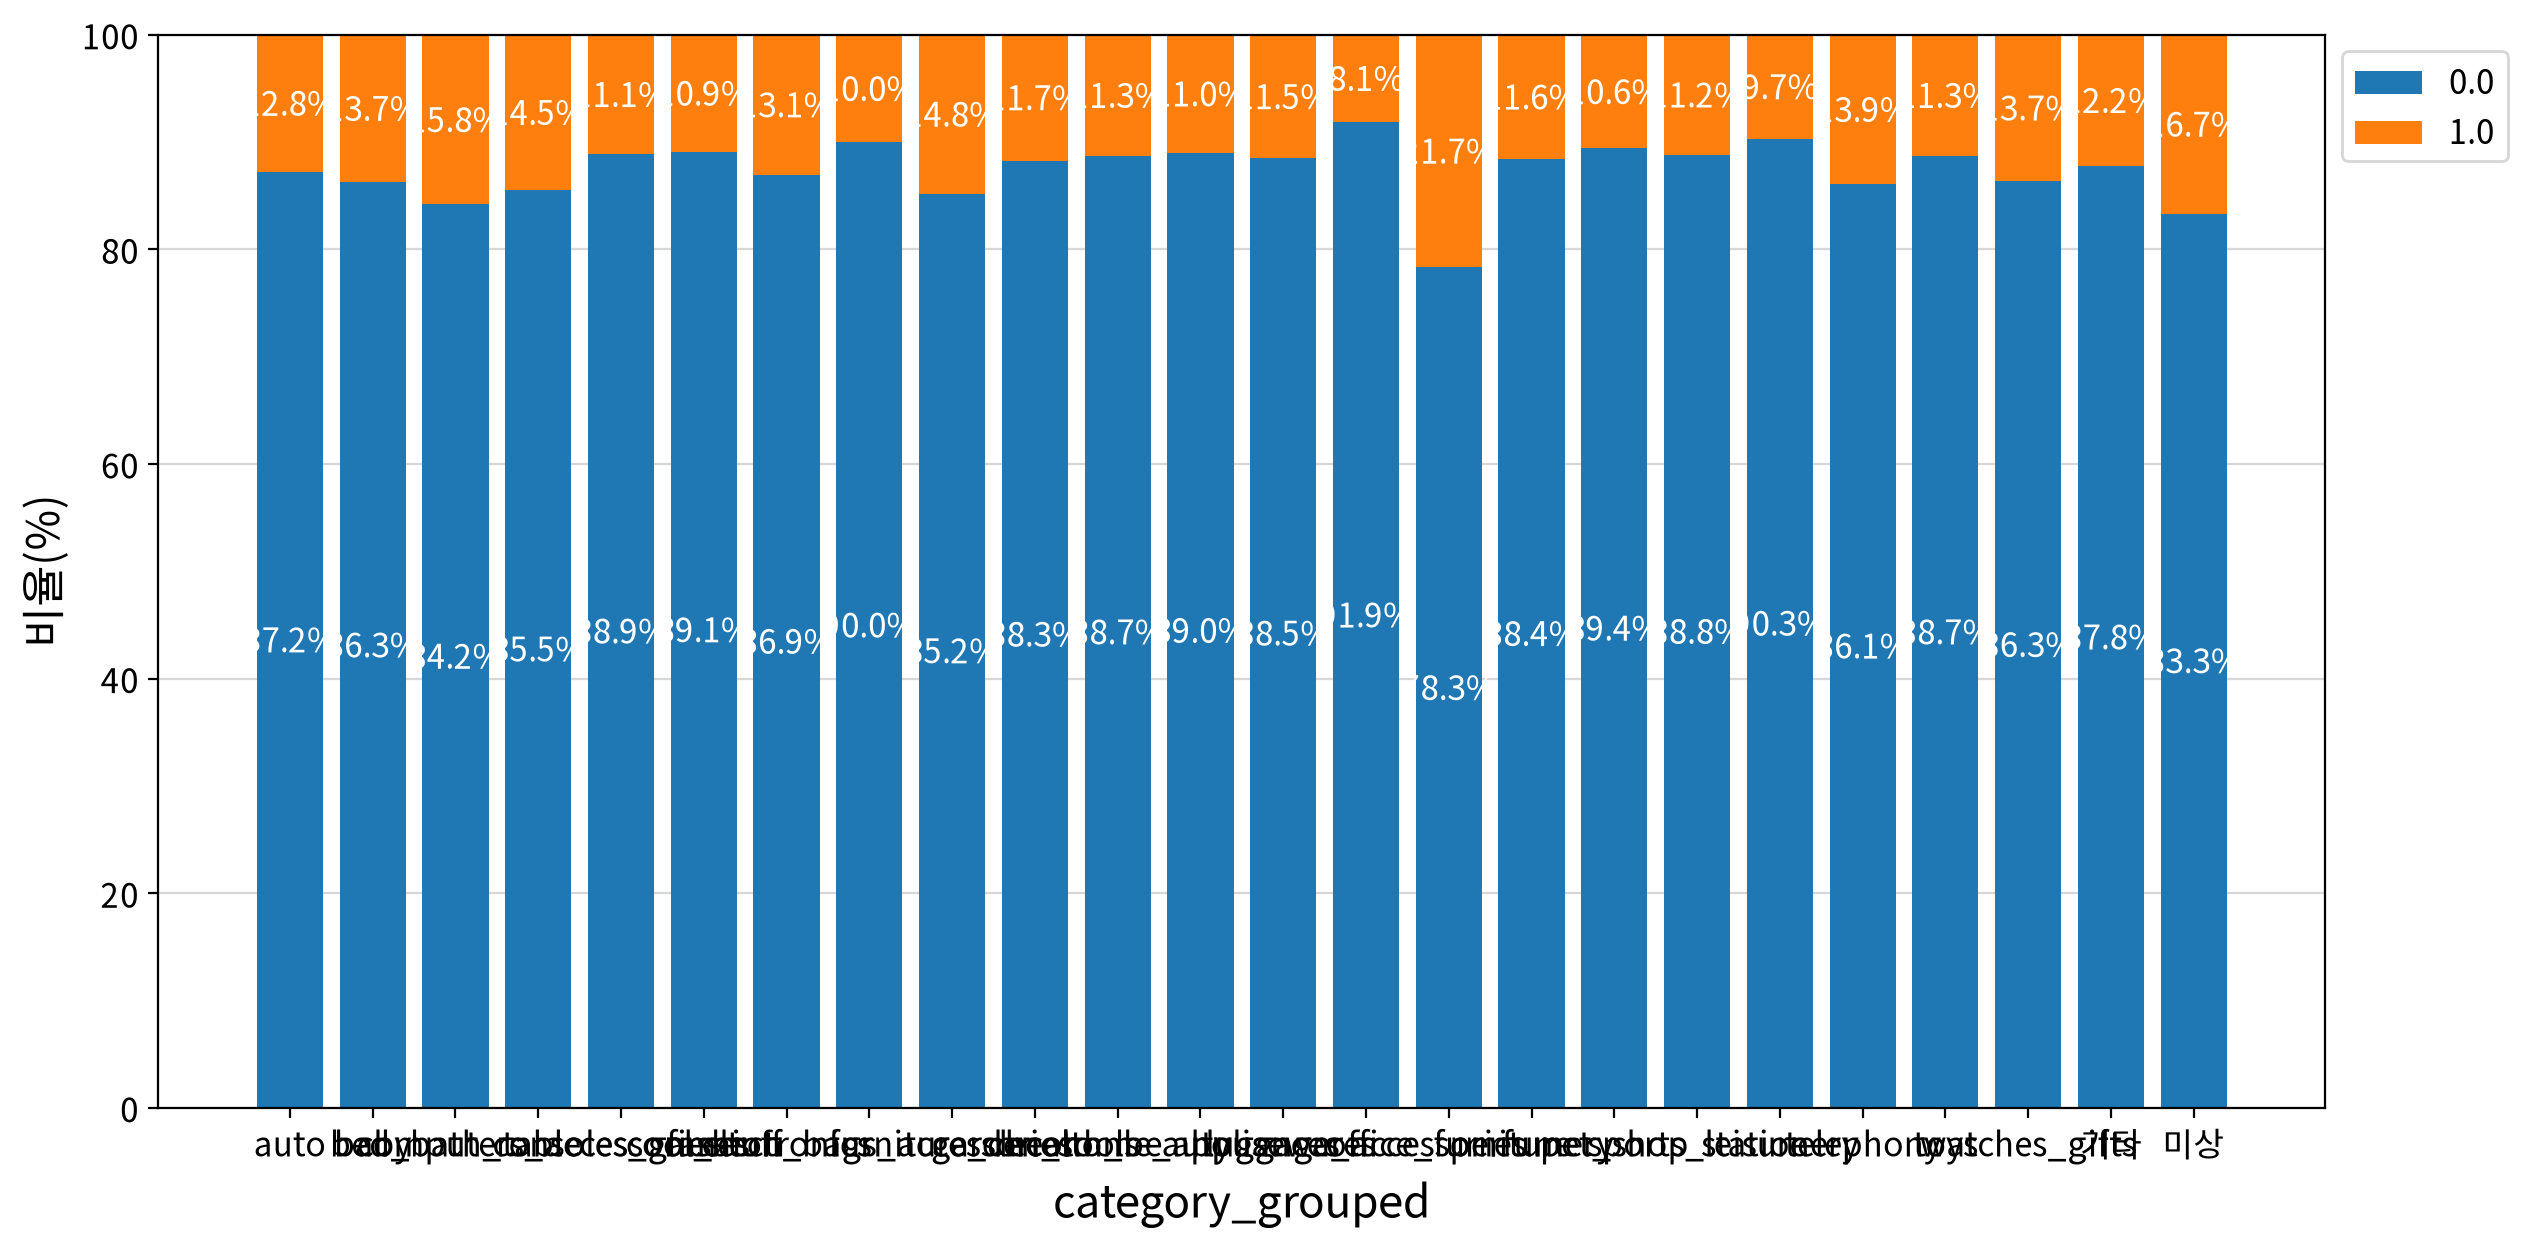

                                                 test      chi2  dof  p-value  \
row              col                                                            
category_grouped low  Chi-square test of independence  363.8473   23      0.0   

                      significant  effect(V)    strength  min_expected  \
row              col                                                     
category_grouped low         True     0.0617  Negligible          95.2   

                      assumption  
row              col              
category_grouped low        True  

기대빈도 5 미만 셀 수: 0 / 48


In [14]:
tmp = master.loc[master["low"].notna(), ["category_grouped", "low"]].copy()

ct = pd.crosstab(tmp["category_grouped"], tmp["low"])
print("교차표 shape:", ct.shape, "(카테고리 수 x low 0/1)")

chi2_result = my_stats.chi2_independence(tmp, x="category_grouped", y="low")
print(chi2_result)

# 기대빈도 5 미만 셀 비율 확인 — 카이제곱 근사가 성립하는지(카테고리 24개라 희귀 카테고리는 걸릴 수 있음)
from scipy.stats import chi2_contingency
_, _, _, expected = chi2_contingency(ct)
n_low_expected = (expected < 5).sum()
print(f"\n기대빈도 5 미만 셀 수: {n_low_expected} / {expected.size}")
if n_low_expected > 0:
    print("⚠️ 카이제곱 근사 가정 위반 가능 — 결과 해석 시 주의 문구 추가 필요")


## 7. 파생변수 저장 (Day6에서 쓸 최종 산출물)

`master`에 지금까지 확정된 파생변수를 전부 담아 parquet으로 저장한다.
저장 전 최종 검증: 행 수 유지(96,204), 핵심 컬럼 결측 0, 컬럼 목록 확인.


In [15]:
# [2026-09-30 추가] 저장 전 정리: delivery_error_days(2-1 비교용 임시 컬럼, cell2에서 생성)와
# seller_id(seller_rep 복사본, cell6 함수 내부에서 생성)는 분석 과정에만 필요했던 중간 산출물이라
# 최종 저장 파일엔 넣지 않는다. 둘 다 EXCLUDE_COLS에도 있지만, "안전장치"(STAGE만 골라쓰기)에
# 기대지 않고 애초에 저장을 안 하는 쪽이 더 안전함.
master = master.drop(columns=["delivery_error_days", "seller_id"])

FEATURE_COLS_STAGE1 = [
    "distance_km_filled", "dist_missing",
    "seller_avg_delay", "seller_avg_delay_is_fallback",
    "category_grouped",
]

assert len(master) == 96204, f"행 수 변경됨: {len(master)}"
for col in FEATURE_COLS_STAGE1:
    n_na = master[col].isna().sum()
    assert n_na == 0, f"{col} 결측 {n_na}건 — 확인 필요"
    print(f"{col}: 결측 0, dtype={master[col].dtype}")

import os
os.makedirs("data/processed", exist_ok=True)
out_path = "data/processed/master_features.parquet"
master.to_parquet(out_path)
print(f"\n저장 완료: {out_path} ({len(master)}행 x {len(master.columns)}컬럼)")
print("컬럼 목록:", master.columns.tolist())


distance_km_filled: 결측 0, dtype=float64
dist_missing: 결측 0, dtype=int64
seller_avg_delay: 결측 0, dtype=float64
seller_avg_delay_is_fallback: 결측 0, dtype=bool
category_grouped: 결측 0, dtype=str

저장 완료: data/processed/master_features.parquet (96204행 x 30컬럼)
컬럼 목록: ['order_id', 'customer_id', 'order_status', 'purchase_ts', 'purchase_month', 'order_approved_at', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'late', 'customer_state', 'seller_state', 'price_sum', 'freight_sum', 'n_items', 'n_sellers', 'installments_max', 'category_en', 'category_pt', 'seller_by_price', 'seller_rep', 'distance_km', 'dist_missing', 'review_id', 'review_score', 'low', 'review_comment_message', 'seller_avg_delay', 'seller_avg_delay_is_fallback', 'category_grouped', 'distance_km_filled']


In [16]:
STAGE2_FEATURES = ["price_sum", "freight_sum", "installments_max"]

EXCLUDE_COLS = [
    "delivery_error_days", "late", "low", "purchase_month",
    "category_en", "category_pt", "distance_km", "seller_by_price",
    "seller_id", "seller_rep", "order_id", "customer_id",
    "order_approved_at", "order_delivered_customer_date", "order_estimated_delivery_date", "purchase_ts",
    "review_id", "review_score", "review_comment_message",
    "order_status",
    "customer_state", "seller_state", "n_items", "n_sellers",
    # customer_state/seller_state: D-04 대체 계산에만 씀, 모델 입력 후보로 안 씀(결정 시 STAGE로 이동)
    # n_items/n_sellers: 계획서 X 목록에 없음, 구매 시점 정보인지 불명확해 보수적으로 제외
]

for col in STAGE2_FEATURES:
    assert col in master.columns, f"{col} 없음"
    assert master[col].isna().sum() == 0, f"{col} 결측 있음"

overlap1 = set(FEATURE_COLS_STAGE1) & set(EXCLUDE_COLS)
overlap2 = set(STAGE2_FEATURES) & set(EXCLUDE_COLS)
assert not overlap1, f"STAGE1과 금지목록 겹침: {overlap1}"
assert not overlap2, f"STAGE2와 금지목록 겹침: {overlap2}"

# [2026-09-30 추가] 전체 컬럼이 STAGE1/STAGE2/EXCLUDE 셋 중 하나에 반드시 속하는지 검사
# (겹침 검사만으로는 "어디에도 없는 컬럼"을 못 잡음 — customer_state/seller_state/
#  n_items/n_sellers가 셋 다 빠져있던 걸 이 assert가 없어서 놓쳤었음)
all_listed = set(FEATURE_COLS_STAGE1) | set(STAGE2_FEATURES) | set(EXCLUDE_COLS)
unlisted = set(master.columns) - all_listed
assert not unlisted, f"어느 목록에도 없는 컬럼: {unlisted}"

print("STAGE1 (1단계 입력):", FEATURE_COLS_STAGE1)
print("STAGE2 (2단계 추가 입력):", FEATURE_COLS_STAGE1 + STAGE2_FEATURES)
print("입력 금지:", EXCLUDE_COLS)
print("\n겹침 없음 확인 완료 (D-16)")


STAGE1 (1단계 입력): ['distance_km_filled', 'dist_missing', 'seller_avg_delay', 'seller_avg_delay_is_fallback', 'category_grouped']
STAGE2 (2단계 추가 입력): ['distance_km_filled', 'dist_missing', 'seller_avg_delay', 'seller_avg_delay_is_fallback', 'category_grouped', 'price_sum', 'freight_sum', 'installments_max']
입력 금지: ['delivery_error_days', 'late', 'low', 'purchase_month', 'category_en', 'category_pt', 'distance_km', 'seller_by_price', 'seller_id', 'seller_rep', 'order_id', 'customer_id', 'order_approved_at', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'purchase_ts', 'review_id', 'review_score', 'review_comment_message', 'order_status', 'customer_state', 'seller_state', 'n_items', 'n_sellers']

겹침 없음 확인 완료 (D-16)


## 결론 (2026-10-30 추가)
- **seller_avg_delay (D-01)**: 현재 주문의 구매시각 이전에 배송이 끝난 같은 셀러 주문의 지연 비율(0\~1). 그런 주문이 20건 미만이면 같은 기준의 전역 지연 비율로 대체한다(전체의 32.4%). 이전 방식(구매 순서만 보고 누적)은 아직 배송 전인 주문의 라벨을 써서 단변량 AUC가 0.6017로 부풀어 있었고, 고친 뒤에는 0.5439다(2-0).
- **한계**: 학습 기간 기준으로 fallback 행의 AUC(0.6236)가 non-fallback(0.5855)보다 높아, 이 변수 신호의 일부는 셀러 품질이 아니라 시기 효과일 수 있다(07 6절에서 확인).
- **min_n·정의 (2-1, 2-2)**: 학습 기간만으로 비교해 min_n=20을 유지했다. delivery_error_days 평균이 단변량 지표로는 조금 나았지만 계획서 원안(late 비율)을 유지했다.
- **category_grouped (D-02)**: '미상'을 뺀 실제 카테고리 상위 22개(90% 커버) + 미상 + 기타 = 24개 범주. 학습 기간만으로 정해도 같은 22개다. 저평점과 독립이 아니지만(카이제곱 p<.001) 효과는 작다(Cramér's V 0.062, 6절).
- **distance_km_filled (D-04)**: 거리 결측 477건을 학습 기간의 customer_state별 평균으로 채우고 dist_missing 더미를 둔다.
- **저장 (7절)**: `data/processed/master_features.parquet`(96,204행 × 30열). 모델 입력 목록(STAGE1·STAGE2)과 입력 금지 목록이 모든 열을 빠짐없이 나눈다는 것을 assert로 확인했다(D-16).